In [14]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from scipy import stats
df = pd.read_csv('apple_stock_data.csv', header=[0, 1], index_col=0, parse_dates=True)
df.index.name = 'Date'
df.columns.names = ['Num', 'Ticker']
df = df.stack(level='Ticker').reset_index()
df = df[['Date', 'Ticker', 'Open', 'High', 'Low', 'Close', 'Volume']]
df.head()

Num,Date,Ticker,Open,High,Low,Close,Volume
0,2021-01-04,A,114.467823,115.574577,112.706630,114.179100,2030700.0
1,2021-01-04,AAPL,129.622521,129.709890,123.059845,125.632492,143301900.0
2,2021-01-04,ABBV,86.159128,86.295785,83.490269,84.736275,9523400.0
3,2021-01-04,ABNB,150.990005,151.005005,137.000000,139.149994,6409900.0
4,2021-01-04,ABT,98.245211,98.891031,96.209090,97.868484,6192000.0


## Data Exploration

In [15]:
df.shape

(700679, 7)

In [16]:
df.columns

Index(['Date', 'Ticker', 'Open', 'High', 'Low', 'Close', 'Volume'], dtype='str', name='Num')

In [17]:
df.dtypes

Num
Date      datetime64[us]
Ticker               str
Open             float64
High             float64
Low              float64
Close            float64
Volume           float64
dtype: object

In [18]:
print('missing values:')
print(df.isnull().sum())

missing values:
Num
Date         0
Ticker       0
Open      9737
High      9737
Low       9737
Close     9737
Volume    9737
dtype: int64


In [19]:
print("Summary Statistics:")
print(df.describe())

Summary Statistics:
Num                          Date           Open           High  \
count                      700679  690942.000000  690942.000000   
mean   2023-10-10 22:13:31.486001     172.568434     174.680831   
min           2021-01-04 00:00:00       0.738000       0.790000   
25%           2022-05-20 00:00:00      55.930000      56.610346   
50%           2023-10-10 00:00:00     104.133270     105.418089   
75%           2025-03-03 00:00:00     197.586095     199.969558   
max           2026-07-22 00:00:00    9914.169922    9964.769531   
std                           NaN     347.751034     351.889730   

Num              Low          Close        Volume  
count  690942.000000  690942.000000  6.909420e+05  
mean      170.423259     172.583416  6.468523e+06  
min         0.710000       0.744000  0.000000e+00  
25%        55.251058      55.934621  1.080700e+06  
50%       102.850373     104.162533  2.313000e+06  
75%       195.224457     197.623463  5.476600e+06  
max      979

In [20]:
print(df.nunique())

Num
Date        1393
Ticker       503
Open      618026
High      621084
Low       620088
Close     596951
Volume    185233
dtype: int64


In [21]:
print(df[['Open', 'High', 'Low', 'Close', 'Volume']].corr())

Num         Open      High       Low     Close    Volume
Num                                                     
Open    1.000000  0.999926  0.999917  0.999841 -0.063446
High    0.999926  1.000000  0.999898  0.999924 -0.063104
Low     0.999917  0.999898  1.000000  0.999929 -0.063807
Close   0.999841  0.999924  0.999929  1.000000 -0.063462
Volume -0.063446 -0.063104 -0.063807 -0.063462  1.000000


In [22]:
mean_vol = df['Volume'].mean()
std_vol = df['Volume'].std()
df['Volume_Z_Score'] = (df['Volume'] - mean_vol) /std_vol
volume_outliers = df[df['Volume_Z_Score'] > 3].sort_values(by='Volume', ascending=False)
print(f"Mean Volume: {mean_vol}")
print(f"Standard Deviation: {std_vol}\n")
print(f"Found {len(volume_outliers)} days with extreme volume:")
print(volume_outliers[['Date', 'Ticker', 'Close', 'Volume', 'Volume_Z_Score']].head(10))

Mean Volume: 6468522.539320232
Standard Deviation: 22288156.706307456

Found 5720 days with extreme volume:
Num          Date Ticker      Close        Volume  Volume_Z_Score
303146 2023-05-25   NVDA  37.859871  1.543911e+09       68.980244
164308 2022-04-20   NFLX  22.618999  1.333875e+09       59.556584
211097 2022-09-01   NVDA  13.882881  1.178865e+09       52.601769
334332 2023-08-24   NVDA  47.018696  1.156044e+09       51.577862
106976 2021-11-04   NVDA  29.670317  1.153631e+09       51.469599
402237 2024-03-08   NVDA  87.279129  1.142269e+09       50.959821
270954 2023-02-23   NVDA  23.585146  1.117995e+09       49.870722
304655 2023-05-31   NVDA  37.714329  1.002580e+09       44.692412
177396 2022-05-26   NVDA  17.777924  9.965750e+08       44.422986
202043 2022-08-08   NVDA  17.723907  9.818590e+08       43.762725


## Hypothesis Testing

Hypothesis Testing 1 (T-test)

H0 = The average Trading volume on down days is equal to or less than average trading volume on up days.

Ha = The average trading volume is signifcantly higher on down days compared to up days

2.980542388839605e-08
Reject the null hypothesis


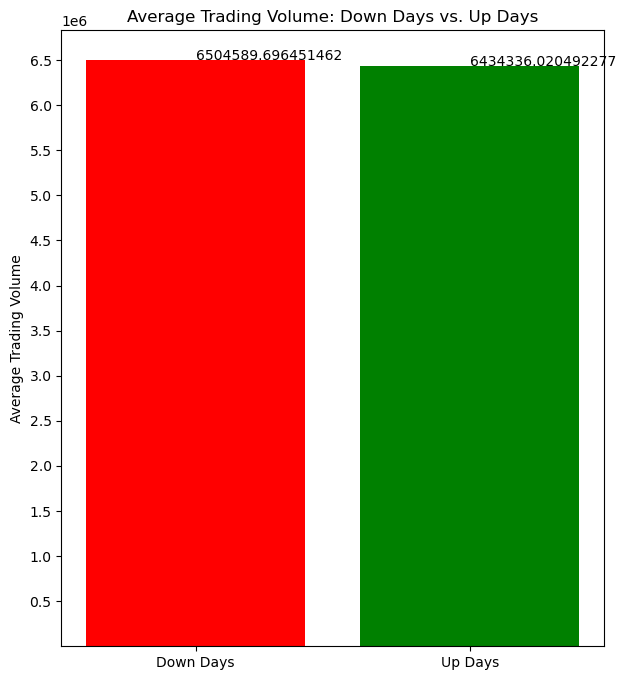

In [36]:
df['Day_Type'] = df.apply(lambda x: 'Down Day' if x['Close']<x['Open'] else 'Up Day', axis = 1)
vol_down = df[df['Day_Type'] == 'Down Day']['Volume'].dropna()
vol_up = df[df['Day_Type'] == 'Up Day']['Volume'].dropna()

u_stat, p_value = stats.mannwhitneyu(vol_down, vol_up, alternative='greater')
print(p_value)
if p_value < 0.05:
    print("Reject the null hypothesis")
else:
    print("Fail to reject the null hypothesis.")
means = [vol_down.mean(), vol_up.mean()]
plt.figure(figsize=(7,8))
plt.bar(['Down Days', 'Up Days'], means, color=['red', 'green'])
plt.title('Average Trading Volume: Down Days vs. Up Days')
plt.ylabel('Average Trading Volume')
plt.yticks([0.5e6,1e6,1.5e6,2e6,2.5e6,3e6,3.5e6,4e6,4.5e6,5e6,5.5e6,6e6,6.5e6])
for i, mean in enumerate(means):
    plt.text(i, mean, f'{mean}')
plt.show()

There is statistically significant evidence that average trading volume is higher on down days than on up days.

Hypothesis Testing 2 (Pearson Correlation)

H0: There is a correlation between a stock's daily price spread (Low-High) and its total trading volume

HA: There isn't a correlation between a stock's daily price spread (Low-High) and its total trading volume

Correlation: -0.028969956860279655
P-value: 3.531214579463785e-128
Conclusion: Reject the null hypothesis.
There is a statistically significant correlation between price spread and volume.


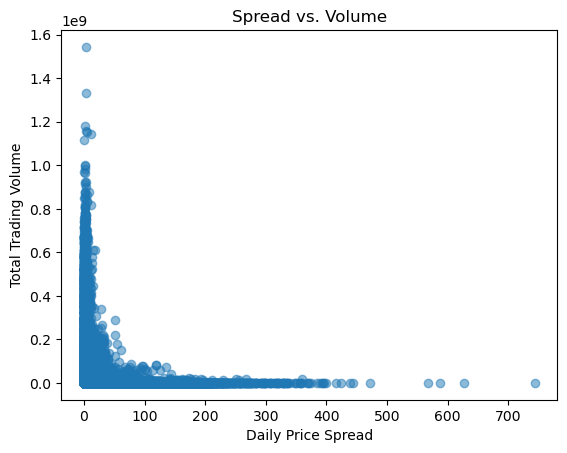

In [24]:
from scipy.stats import pearsonr
df = df.dropna(subset = ['High', 'Low', 'Volume'])
df['Spread'] = df['High'] - df['Low']

corr, p_value = pearsonr(df['Spread'], df['Volume'])

print(f"Correlation: {corr}")
print(f"P-value: {p_value}")

alpha = 0.05
if p_value < alpha:
    print("Conclusion: Reject the null hypothesis.")
    print("There is a statistically significant correlation between price spread and volume.")
else:
    print("Conclusion: Fail to reject the null hypothesis.")
    print("There is no statistically significant correlation between price spread and volume.")

plt.scatter(df['Spread'], df['Volume'], alpha=0.5)

plt.xlabel('Daily Price Spread')
plt.ylabel('Total Trading Volume')
plt.title('Spread vs. Volume')

plt.show()

Hypothesis Testing 3 (one way ANOVA)

Use ANOVA testing to determine if there is a statistically significant difference depending on the day of the week.

H0 = There is no difference in the trading volume depending on the day of week

Ha = There is a difference in the trading volume depending on the day of week

In [12]:
from scipy.stats import f_oneway
df["Day of Week"] = df["Date"].dt.day_name()
volume = df.groupby(["Ticker", "Day of Week"])["Volume"].mean().reset_index()
temp_storage = {"Ticker": [], "Statistic": [], "P-Value": []}

for ticker in df["Ticker"].unique():
    stock = df[df["Ticker"] == ticker]

    anova = f_oneway(
        stock[stock["Day of Week"] == "Monday"]["Volume"],
        stock[stock["Day of Week"] == "Tuesday"]["Volume"],
        stock[stock["Day of Week"] == "Wednesday"]["Volume"],
        stock[stock["Day of Week"] == "Thursday"]["Volume"],
        stock[stock["Day of Week"] == "Friday"]["Volume"]
    )

    temp_storage["Ticker"].append(ticker)
    temp_storage["Statistic"].append(anova.statistic)
    temp_storage["P-Value"].append(anova.pvalue)

anova_df = pd.DataFrame(temp_storage)

significant = anova_df[anova_df["P-Value"] < 0.05]

display(anova_df.head())

print(f"Number of statistically significant results (pvalue < 0.05) / total results: "
      f"{len(significant)} / {anova_df.shape[0]} = {len(significant)/anova_df.shape[0]}")


,Ticker,Statistic,P-Value
0,A,3.125971,0.014258
1,AAPL,6.224410,0.000058
2,ABBV,6.577079,0.000030
3,ABNB,2.624759,0.033254
4,ABT,2.073899,0.081947


Number of statistically significant results (pvalue < 0.05) / total results: 213 / 503 = 0.4234592445328032


So based on the results, we can see that for roughly 42.35% of the different companies, we can reject the null hypothesis and confirm that there is a difference in trading volume depending on the day of the week. For the other companies, we do not have enough evidence to conclude there is a difference and we fail to reject the null hypothesis.

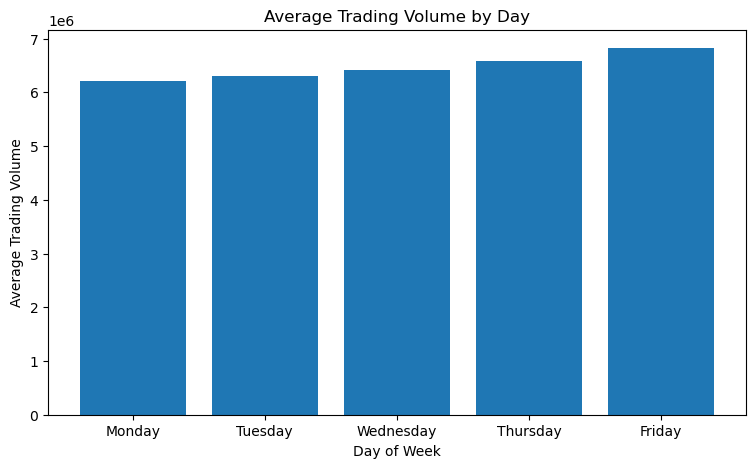

In [13]:
days = ["Monday", "Tuesday", "Wednesday", "Thursday", "Friday"]
avg_volume = df.groupby("Day of Week")["Volume"].mean()
avg_volume = avg_volume.reindex(days)
plt.figure(figsize=(9,5))
plt.bar(days, avg_volume)
plt.xlabel("Day of Week")
plt.ylabel("Average Trading Volume")
plt.title("Average Trading Volume by Day")
plt.show()